# UUV closed-loop depth control demo

Simulates the submarine following the depth reference in `data/mission.csv` with a discrete-time PD controller, under random disturbances.

In [1]:
# Make the uuv_mission package importable from the notebooks/ folder
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
sys.path.append(str(REPO_ROOT))

In [2]:
import numpy as np

from uuv_mission.dynamic import Submarine, ClosedLoop, Mission
from uuv_mission.control import PDController

In [3]:
# Build the closed loop: plant + PD controller (KP = 0.15, KD = 0.6)
controller = PDController(kp=0.15, kd=0.6)
closed_loop = ClosedLoop(Submarine(), controller)

# Load the mission (reference depth and cave limits) from the CSV
mission = Mission.from_csv(REPO_ROOT / "data" / "mission.csv")

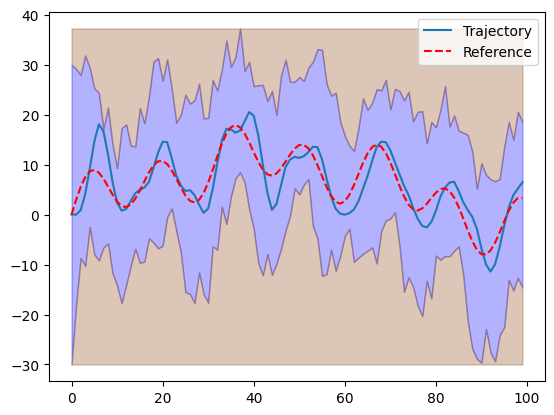

In [4]:
# Fixed seed so the disturbance sequence, and hence the plot, is reproducible
np.random.seed(0)

trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)